# Plot of transects for how fraction of water varies downstream

The following notebook includes the code that is used to create Figure S4 in the accompanying study.

In [1]:
import os

import cartopy
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import json
import matplotlib as mpl
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import ListedColormap
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
import matplotlib.path as mpath
import matplotlib.patches as patches
from matplotlib.patches import FancyArrowPatch
from matplotlib.patches import Polygon
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import AutoMinorLocator
from matplotlib.ticker import MultipleLocator, FixedLocator
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize
from scipy.ndimage import uniform_filter
from scipy.spatial import ConvexHull
from scipy.spatial import cKDTree
from shapely.geometry import Point
from tqdm import tqdm
import xarray as xr

In [2]:
main_directory = os.getcwd()

# data_fp = 'RiverTransects/'

# ssps = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
ssps = ['126', '245', '370', '585']
gcm_names = ['BCC-CSM2-MR', 'CESM2', 'CESM2-WACCM', 'EC-Earth3', 'EC-Earth3-Veg', 'FGOALS-f3-L', 
             'GFDL-ESM4', 'INM-CM4-8', 'INM-CM5-0', 'MPI-ESM1-2-HR', 'MRI-ESM2-0', 'NorESM2-MM']

# Plotting details
ssp_name_dict = {'126':'SSP1-2.6',
                 '245':'SSP2-4.5',
                 '370':'SSP3-7.0',
                 '585':'SSP5-8.5',
                 'ssp126':'SSP1-2.6',
                 'ssp245':'SSP2-4.5',
                 'ssp370':'SSP3-7.0',
                 'ssp585':'SSP5-8.5'
                }
ssp_colordict = {'119':'#081d58', '126':'#1d91c0', '245':'#7fcdbb', '370':'#F47A20', '585':'#ED2024'}

In [3]:
rivers_df = pd.read_csv('wbm_data/wbm_rivers/MERIT_plus_15min_v1_IDs_super.csv')
rivers_df

,ID,Name,Area,src_ID,SeaCode,SeaName,OceanCode,OceanName,SubContinentCode,SubContinentName,Endorheic,Glaciers,Glaciers_IBT
0,1,Amazon,5945331.07,1.0,32,Atlantic Ocean,4,Atlantic Ocean,11,South America,0,1,none
1,2,Zaire,3697581.39,3.0,32,Atlantic Ocean,4,Atlantic Ocean,0,Africa,0,0,none
2,3,NaN,3278637.42,NaN,8,Caspian Sea,0,Land,2,Asia,1,1,36
3,4,Nile,3110922.57,2.0,2,Mediterranean Sea,2,Mediterranean+Black Sea,0,Africa,0,1,none
4,5,Parana,3002826.39,6.0,32,Atlantic Ocean,4,Atlantic Ocean,11,South America,0,1,none
...,...,...,...,...,...,...,...,...,...,...,...,...,...
33168,36387,NaN,85.97,NaN,128,Arctic subocean,128,Arctic Ocean,5,Greenland,0,0,none
33169,36388,NaN,85.97,NaN,128,Arctic subocean,128,Arctic Ocean,5,Greenland,0,0,none
33170,36389,NaN,85.97,NaN,128,Arctic subocean,128,Arctic Ocean,5,Greenland,0,0,none
33171,36390,NaN,85.97,NaN,128,Arctic subocean,128,Arctic Ocean,5,Greenland,0,1,none


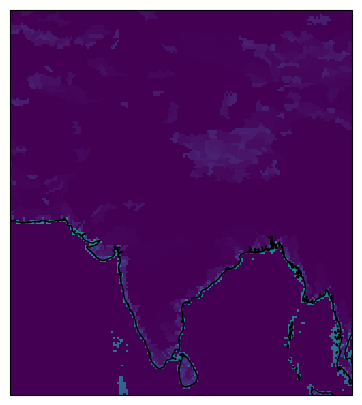

In [4]:
river_fn = 'wbm_data/wbm_rivers/MERIT_plus_15min_v1_IDs_wcrs-wibt.tif'

with rasterio.open(river_fn) as dataset:
    # Read the first band into a NumPy array
    river_array = dataset.read(1)
    transform = dataset.transform
    height, width = dataset.height, dataset.width

# Create row/col index grids
rows, cols = np.meshgrid(np.arange(height), np.arange(width), indexing='ij')

# Convert pixel indices to coordinates
xs, ys = rasterio.transform.xy(transform, rows, cols)

# Convert to arrays
lon = np.array(xs)
lat = np.array(ys)

lons = lon[0,:]
lats = lat[:,0]

river_array[river_array<0] = 0

fig, ax = plt.subplots(
    figsize=(10, 5),
    subplot_kw={"projection": ccrs.PlateCarree()}  # nice global projection
)


im = ax.pcolormesh(lons, lats, river_array, transform=ccrs.PlateCarree(),
                       # cmap=cmap1, 
                       # norm=norm1, 
                       zorder=0)

# ax.set_global()
ax.set_extent([60, 100, 5, 50], crs=ccrs.PlateCarree())
ax.coastlines()

plt.show()

In [5]:
qmax_fp = 'wbm_data/discharge_month_max/'

# Historical 
qmax_fn = 'historical_max_discharge_m3s_pg_frac.nc'
ds_qmax = xr.open_dataset(qmax_fp + qmax_fn)
qmax = ds_qmax['max_monthly_frac'].values

qmax_2006_2015 = np.mean(qmax[-10:,:,:], axis=0)

In [6]:
# ssp = 'ssp245'
# qmax_fp = 'wbm_data/discharge_month_max/'

# qmax_gcms = None
# for ngcm, gcm_name in enumerate(gcm_names):

#     qmax_fn = gcm_name + '_' + ssp + '_max_discharge_m3s_pg_frac.nc'

#     ds_qmax = xr.open_dataset(qmax_fp + qmax_fn)

#     qmax = ds_qmax['max_monthly_frac'].values

#     if qmax_gcms is None:
#         qmax_gcms = qmax[np.newaxis,:,:,:]
#     else:
#         qmax_gcms = np.concatenate((qmax_gcms, qmax[np.newaxis,:,:,:]), axis=0)

# # 2016-2025
# qmax_gcms_2016_2025_mean = np.nanmean(qmax_gcms[:,0:10,:,:], axis=1)
# qmax_multigcm_med_2016_2025 = np.nanmedian(qmax_gcms_2016_2025_mean, axis=0)

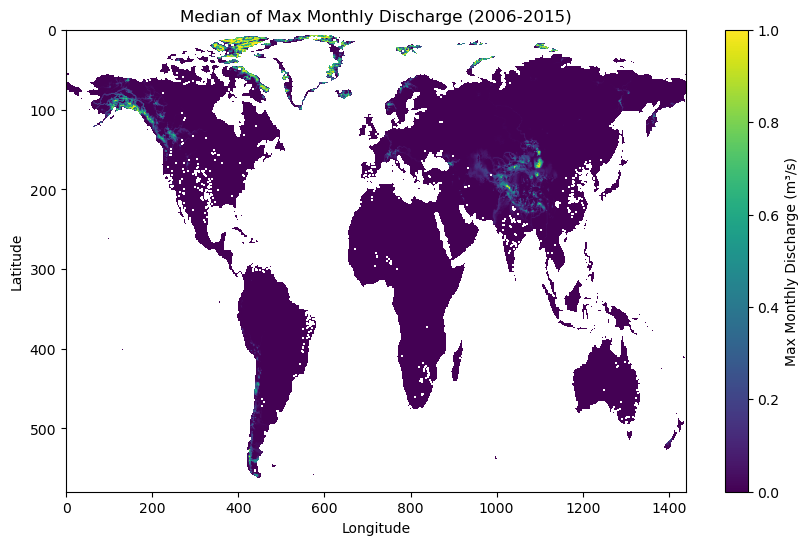

In [7]:
# Plotting qmax_2006_2015
plt.figure(figsize=(10, 6))
plt.imshow(qmax_2006_2015, cmap='viridis', aspect='auto')
plt.colorbar(label='Max Monthly Discharge (m³/s)')
plt.title('Median of Max Monthly Discharge (2006-2015)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(False)
plt.show()

# Add distance, continents, glacier fraction to the elevation data
This ensures there is distance and elevation to use for analyses

In [8]:
def distance_geopandas(lat1, lon1, lat2, lon2):
    """From ChatGPT and verified manually that it's correct for glaciers in HMA"""
    # Create GeoSeries
    gdf = gpd.GeoSeries([
        Point(lon1, lat1),
        Point(lon2, lat2)
    ], crs="EPSG:4326")

    # Auto-project to appropriate UTM zone
    gdf_utm = gdf.to_crs(gdf.estimate_utm_crs())

    # Compute distance
    return gdf_utm.iloc[0].distance(gdf_utm.iloc[1])

In [9]:
dem_nc_fp = 'DEM/'
dem_fn_wdist = 'dem_wdist_cont_frac.nc'

if not os.path.exists(dem_nc_fp + dem_fn_wdist):

    # ----- DEM -----
    dem_nc_fn = 'dem.nc'
    ds_elev = xr.open_dataset(dem_nc_fp + dem_nc_fn)
    elevation = ds_elev['elev'].values
    lat = ds_elev['latitude'].values
    lon = ds_elev['longitude'].values
    
    # ----- GLACIERS -----
    rgi_shp_fn = 'rgi_regions/rgi60_all_simplified2_minpt5.shp'
    rgi_gdf = gpd.read_file(rgi_shp_fn)
    
    rgi_O2_shp_fn = 'rgi_regions/00_rgi60_O2Regions.shp'
    rgi_O2_gdf = gpd.read_file(rgi_O2_shp_fn)
    rgi_O2_gdf = rgi_O2_gdf.to_crs('EPSG:4326')
    
    # remove subregions that don't have large enough glaciers in them
    good_rgiO2_idxs = []
    for idx in rgi_O2_gdf.index.values:
        rgiO1, rgiO2 = rgi_O2_gdf.loc[idx, 'RGI_CODE'].split('-')
        rgi_gdf_subset = rgi_gdf[(rgi_gdf['O1Region'] == str(int(rgiO1))) & (rgi_gdf['O2Region'] == str(int(rgiO2)))]
    
        if (rgi_gdf_subset.shape[0] > 0) and (rgiO1 not in ['19']):
            good_rgiO2_idxs.append(idx)
    
    rgi_O2_gdf = rgi_O2_gdf.loc[good_rgiO2_idxs].reset_index(drop=True)
    
    # ----- CONTINENTS -----
    cont_fp = 'ipcc_regions/'
    cont_fn = 'IPCC-WGII-continental-regions.geojson'
    cont_raster_fn = "IPCC-WGII-continental-regions-id.nc"
    
    cont_gdf = gpd.read_file(cont_fp + cont_fn)
    ds_cont = xr.open_dataset(cont_fp + cont_raster_fn)
    cont_name2id = dict(zip(cont_gdf["Name"], cont_gdf["id"]))
    
    # add it to the elevation data
    ds_elev['cont_id'] = ds_cont.cont_id
    
    # ----- DOMESTIC FRACTION -----
    dom_pg_frac_fp = 'wbm_data/domestic_pg_frac/'
    dom_pg_frac_fn = 'historical_dom_pg.shp'
    
    # ----- Load Fraction Data ----
    dom_pg_frac_gdf = gpd.read_file(dom_pg_frac_fp + dom_pg_frac_fn)
    dom_pg_frac_gdf['2006-2015'] = dom_pg_frac_gdf.loc[:,[str(x) for x in range(2006,2016)]].mean(axis=1)
    
    # Extract latitude, longitude, and population data
    latitudes = ds_elev['latitude'].values
    longitudes = ds_elev['longitude'].values
    
    
    # Rasterize the domestic fraction data
    raster_values = np.zeros(ds_elev.elev.shape)
     
    # Define the transform for the raster (assuming equal resolution for simplicity)
    transform = rasterio.transform.from_origin(longitudes[0], latitudes[0], 
                                               abs(longitudes[1] - longitudes[0]), 
                                               abs(latitudes[1] - latitudes[0]))
     
    # Rasterize the '2006-2015' values from the GeoDataFrame
    shapes = ((geom, value) for geom, value in zip(dom_pg_frac_gdf.geometry, dom_pg_frac_gdf['2006-2015']))
    rasterized = rasterize(shapes, out_shape=ds_elev.elev.shape, transform=transform, fill=0, all_touched=True)
     
    # Update raster_values with rasterized data
    raster_values += rasterized
    raster_values[raster_values == 0] = np.nan
    
    # Add the rasterized values as a new variable to the ds_elev dataset
    ds_elev['dom_pg_frac_2006_2015'] = (('latitude', 'longitude'), raster_values)


    # ----- ADD DISTANCE -----
    # Get the indices of good points where there is glacier-sourced water from rivers and domestic use
    indices_qmax = np.where(qmax_2006_2015 > 0.01)
    indices_dom_pg_frac = np.where(ds_elev['dom_pg_frac_2006_2015'] > 0.01)
    
    combined_indices = np.unique(np.concatenate((indices_dom_pg_frac, indices_qmax), axis=1), axis=1)
     
    # Print or return the combined indices
    combined_indices
    
    lats_good = combined_indices[0]
    lons_good = combined_indices[1]
    
    print('lat min/max:', 
          np.min(latitudes[lats_good]), np.max(latitudes[lats_good]), 
          '\nlon min/max:', 
          np.min(longitudes[lons_good]), np.max(longitudes[lons_good]))

    import warnings
    warnings.filterwarnings("ignore", category=UserWarning) # removes the first distance which is just to get RGI region
    
    pixel_distances = []
    for nidx in tqdm(range(0,lats_good.shape[0])):
        lat = latitudes[lats_good[nidx]]
        lon = longitudes[lons_good[nidx]]
    
        point = Point(lon, lat)
    
        # Find nearest polygon
        rgi_O2_distances = rgi_O2_gdf.geometry.distance(point)
        nearest_idx = rgi_O2_distances.idxmin()
    
        rgiO1, rgiO2 = rgi_O2_gdf.loc[nearest_idx, 'RGI_CODE'].split('-')
        rgiO1, rgiO2 = rgiO1.lstrip('0'), rgiO2.lstrip('0')

        # Subset glacier data
        rgi_gdf_subset = rgi_gdf[(rgi_gdf['O1Region'] == rgiO1) & (rgi_gdf['O2Region'] == rgiO2)].reset_index(drop=True)

        # KDTree on center points
        centers = rgi_gdf_subset[['CenLon', 'CenLat']].values
        tree = cKDTree(centers)
    
        _, idx = tree.query([lon, lat])
    
        # Final distance (using your function)
        dist = distance_geopandas(
            lat, lon,
            rgi_gdf_subset.loc[idx, 'CenLat'],
            rgi_gdf_subset.loc[idx, 'CenLon']
        )
        pixel_distances.append(dist)

    # Initialize the dist_glac variable with NaNs
    dist_glac = np.full(ds_elev.elev.shape, np.nan)
    
    # Assign distances to the correct indices in dist_glac
    dist_glac[lats_good, lons_good] = pixel_distances

    # Add the rasterized values as a new variable to the ds_elev dataset
    ds_elev['dist_glac'] = (('latitude', 'longitude'), dist_glac)

    # Export new file
    ds_elev.to_netcdf(dem_nc_fp + dem_fn_wdist)

else:
    ds_elev = xr.open_dataset(dem_nc_fp + dem_fn_wdist)

In [10]:
# ds_elev.dom_pg_frac_2006_2015.plot()
# ds_elev.elev.plot()
# ds_elev.dist_glac.plot()

ds_elev

<xarray.Dataset>
Dimensions:                (latitude: 580, longitude: 1440)
Coordinates:
  * latitude               (latitude) float64 84.88 84.62 ... -59.62 -59.88
  * longitude              (longitude) float64 -179.9 -179.6 ... 179.6 179.9
Data variables:
    elev                   (latitude, longitude) float64 ...
    cont_id                (latitude, longitude) float32 ...
    dom_pg_frac_2006_2015  (latitude, longitude) float64 ...
    dist_glac              (latitude, longitude) float64 ...

# Process Transects

#### spatially-varying q_threshold based on distance from glacier

In [11]:
dist_glac = ds_elev.dist_glac.values

q_threshold = np.zeros(dist_glac.shape) + 100
q_threshold[dist_glac<1000] = 1
q_threshold[dist_glac<5000] = 5
q_threshold[dist_glac<25000] = 10
q_threshold[dist_glac<50000] = 20
q_threshold[dist_glac<100000] = 50

q_pg_threshold = 0.01

In [12]:
q_fp = 'wbm_data/historical_discharge/'
q_fn = 'yearly_ave_m3s.nc'
ds_q = xr.open_dataset(q_fp + q_fn)

q = ds_q.discharge_yc.values
q[q<q_threshold] = np.nan
q[qmax_2006_2015 < q_pg_threshold] = np.nan

### Create dictionary to store attributes of interest

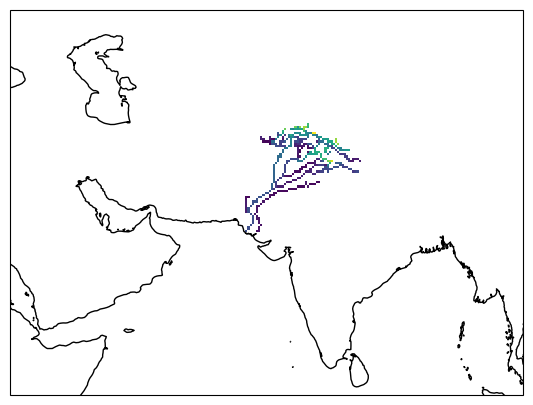

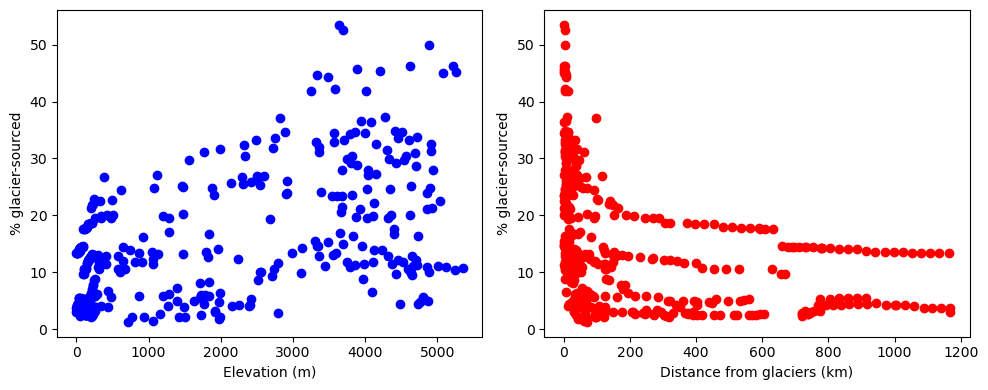

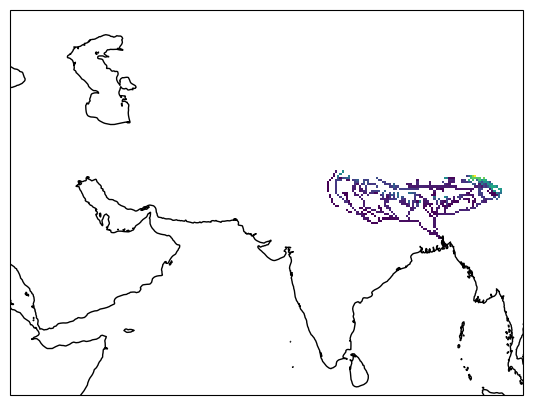

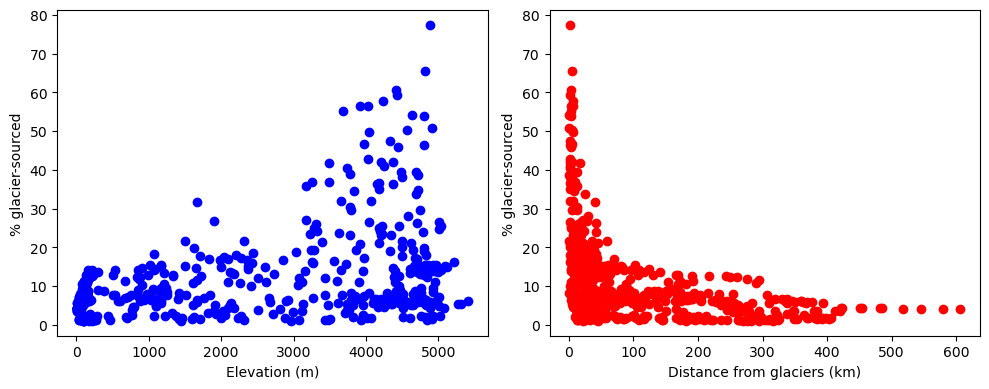

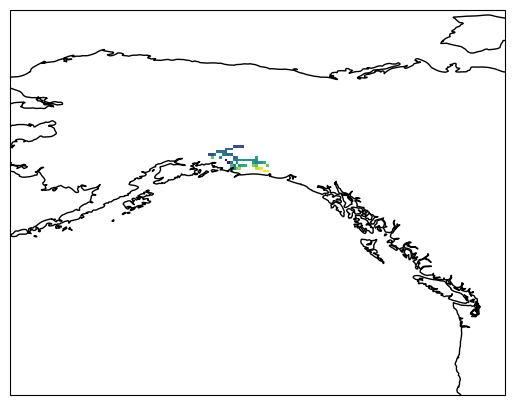

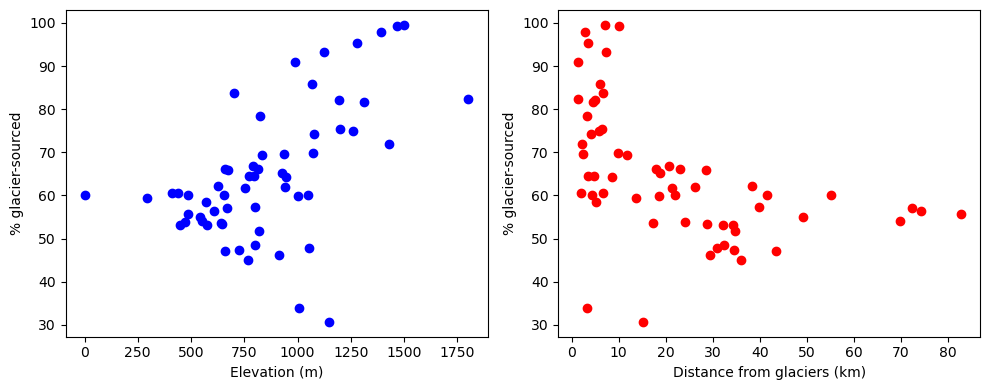

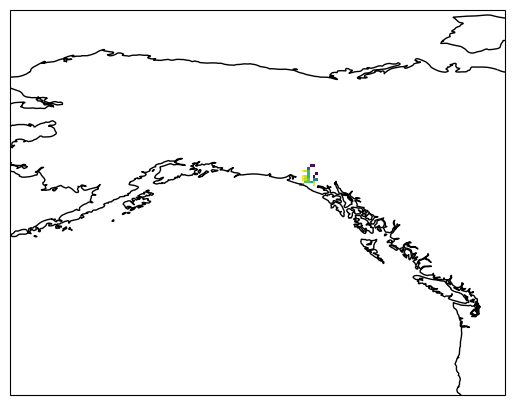

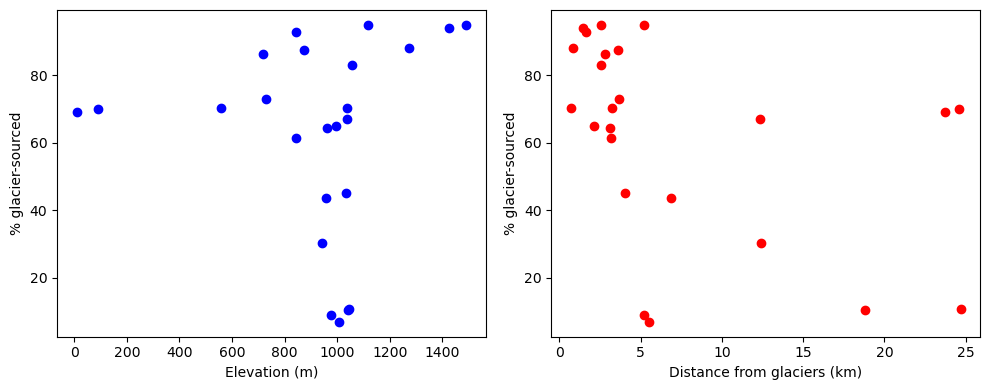

In [13]:
river_id_dict = {'Amu-Darya':3}

river_names = ['Indus', 'Ganges', 'Copper', 'Alsek']

river_value_dict = {}

for river_name in river_names:
    if river_name in river_id_dict.keys():
        river_id = river_id_dict[river_name]
    else:
        river_id = rivers_df.loc[rivers_df['Name'] == river_name, 'ID'].values
    
    with rasterio.open(river_fn) as dataset:
        # Read the first band into a NumPy array
        river_array = dataset.read(1)
        transform = dataset.transform
        height, width = dataset.height, dataset.width
    
    # Create row/col index grids
    rows, cols = np.meshgrid(np.arange(height), np.arange(width), indexing='ij')
    
    # Convert pixel indices to coordinates
    xs, ys = rasterio.transform.xy(transform, rows, cols)
    
    # Convert to arrays
    lon = np.array(xs)
    lat = np.array(ys)
    
    lons = lon[0,:]
    lats = lat[:,0]

    # River data
    river_array[river_array<0] = 0
    river_array[river_array!=river_id] = 0
    river_array[np.isnan(q)] = 0

    # Elevation data
    elev2plot = ds_elev.elev.values.copy()
    elev2plot[river_array<0] = np.nan
    elev2plot[river_array!=river_id] = np.nan
    elev2plot[np.isnan(q)] = np.nan

    # Fraction data
    qfrac = 100*qmax_2006_2015.copy()
    qfrac[river_array<0] = np.nan
    qfrac[river_array!=river_id] = np.nan
    qfrac[np.isnan(q)] = np.nan

    # Distance data
    dist = dist_glac.copy()
    dist[river_array<0] = np.nan
    dist[river_array!=river_id] = np.nan
    dist[np.isnan(q)] = np.nan

    # Store values
    river_value_dict[river_name] = [qfrac, elev2plot, dist]
    
    # ---- PLOT -----
    fig, ax = plt.subplots(
        figsize=(10, 5),
        subplot_kw={"projection": ccrs.PlateCarree()}  # nice global projection
    )
    
    
    im = ax.pcolormesh(lons, lats, qfrac, transform=ccrs.PlateCarree(),
                           # cmap=cmap1, 
                           # norm=norm1, 
                           zorder=0)
    
    # ax.set_global()
    if river_name in ['Ganges', 'Indus', 'Amu-Darya']:
        ax.set_extent([40, 100, 5, 50], crs=ccrs.PlateCarree())
    elif river_name in ['Yukon', 'Copper', 'Mackenzie', 'Alsek'] or river_id in [306]:
        ax.set_extent([-165, -120, 40, 75], crs=ccrs.PlateCarree())
    elif river_name in ['Rhone', 'Rhine']:
        ax.set_extent([-10, 30, 34, 55], crs=ccrs.PlateCarree())
        
    ax.coastlines()
    
    plt.show()

    # ---- PLOT RELATIONSHIPS -----
    # Create subplots (1 row, 2 columns)
    fig, axs = plt.subplots(1, 2, figsize=(10, 4))
    
    
    axs[0].scatter(elev2plot, qfrac, color='blue')
    axs[0].set_ylabel('% glacier-sourced')
    axs[0].set_xlabel('Elevation (m)')
    
    axs[1].scatter(dist/1e3, qfrac, color='red')
    axs[1].set_ylabel('% glacier-sourced')
    axs[1].set_xlabel('Distance from glaciers (km)')
    
    plt.tight_layout()
    plt.show()

## Plot altogether

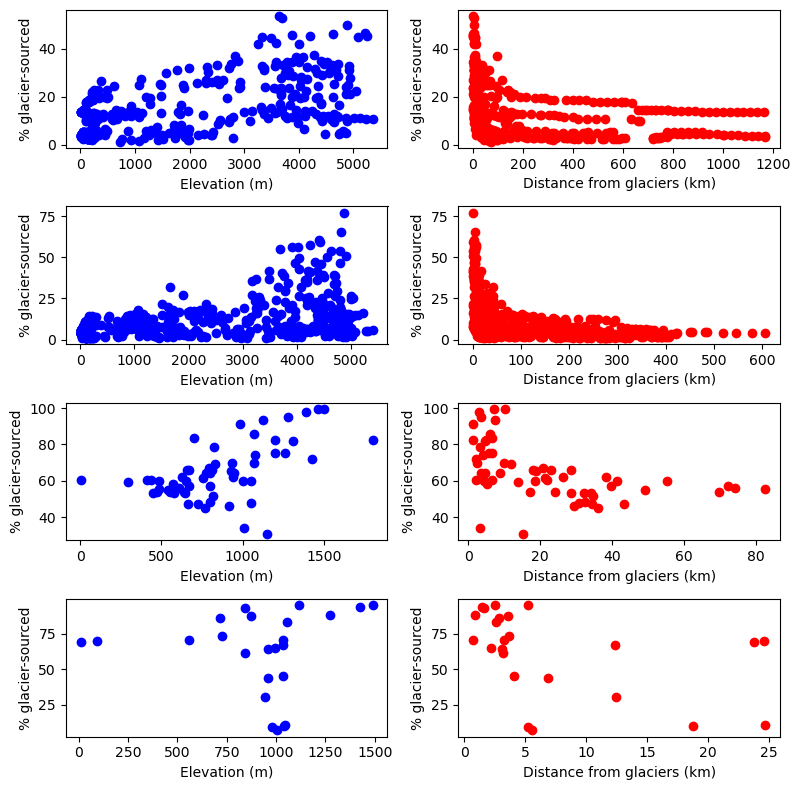

In [14]:
# ---- PLOT RELATIONSHIPS -----
fig, axs = plt.subplots(len(river_names), 2, figsize=(8, 8))

for nriver, river_name in enumerate(river_names):
    value_list = river_value_dict[river_name]
    qfrac = value_list[0]
    elev2plot = value_list[1]
    dist = value_list[2]

    axs[nriver,0].scatter(elev2plot, qfrac, color='blue')
    axs[nriver,0].set_ylabel('% glacier-sourced')
    axs[nriver,0].set_xlabel('Elevation (m)')
    
    axs[nriver,1].scatter(dist/1e3, qfrac, color='red')
    axs[nriver,1].set_ylabel('% glacier-sourced')
    axs[nriver,1].set_xlabel('Distance from glaciers (km)')

plt.tight_layout()
plt.show()

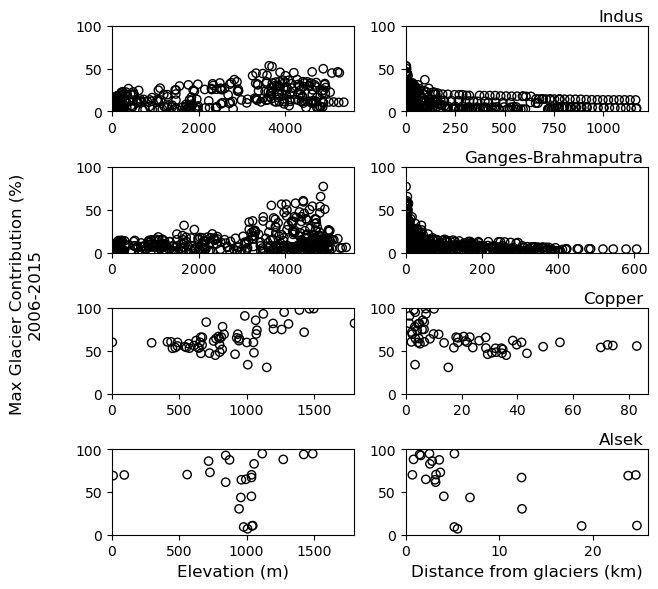

In [15]:
# ---- PLOT RELATIONSHIPS -----
# Create subplots (1 row, 2 columns)
fig, axs = plt.subplots(len(river_names), 2, figsize=(6.5, 6))

for nriver, river_name in enumerate(river_names):
    value_list = river_value_dict[river_name]
    qfrac = value_list[0]
    elev2plot = value_list[1]
    dist = value_list[2]

    # Elevation
    axs[nriver,0].scatter(elev2plot, qfrac, color='k', 
                          fc='none'
                         )
    axs[nriver,0].set_ylim(0,100)
    if river_name in ['Indus', 'Ganges']:
        elev_max = 5600
    elif river_name in ['Copper', 'Alsek']:
        elev_max = 1800
    axs[nriver,0].set_xlim(0,elev_max)
    

    # Distance
    axs[nriver,1].scatter(dist/1e3, qfrac, color='k', 
                          fc='none'
                         )
    axs[nriver,1].set_ylim(0,100)
    axs[nriver,1].set_xlim(left=0)

    # River Names
    if river_name in ['Ganges']:
        river_name_2plot = 'Ganges-Brahmaputra'
    else:
        river_name_2plot = river_name
    axs[nriver,1].text(0.98, 1.02, river_name_2plot,
        transform=axs[nriver,1].transAxes,  ha='right', va='bottom', fontsize=12)

    # Axis labels
    if nriver == len(river_names)-1:
        axs[nriver,0].set_xlabel('Elevation (m)', size=12)
        axs[nriver,1].set_xlabel('Distance from glaciers (km)', size=12)

# Y-label
fig.supylabel('Max Glacier Contribution (%)\n2006-2015', ha='center', va='center', fontsize=12)

plt.tight_layout()

fig.savefig('figures_paper/figS4_river-transects_elev_distance_vs_perc.png', bbox_inches='tight', dpi=300)

plt.show()